Import

In [ ]:
import pandas as pd
import re
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import time
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr
import os
import json

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

Dataset Location, Preprocessing

In [ ]:
DATA_DIR = "../data/"
path_sarcasm = os.path.join(DATA_DIR, "idsarcasm/")
path_indonlu = os.path.join(DATA_DIR, "indonlu/")

# Cleaning
def clean_tweet(text):
    if not isinstance(text, str):
        return ""
    # Delete Tags
    text = re.sub(r'<username>', '', text)
    text = re.sub(r'<hashtag>', '', text)
    text = re.sub(r'<link>', '', text)
    text = re.sub(r'<url>', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    # Case Folding
    text = text.lower()
    return text

# Load, Filter, Combine, Save
def process_and_combine(sarcasm_file, indonlu_file, output_filename):
    print(f"Membaca file:\n- {sarcasm_file}\n- {indonlu_file}")

    # Process IdSarcasm Data
    df_sarcasm = pd.read_csv(sarcasm_file)
    df_sarcasm = df_sarcasm[df_sarcasm['label'] == 1].copy()
    df_sarcasm = df_sarcasm.rename(columns={'tweet': 'text'})
    df_sarcasm['label'] = 'sarcasm'

    # Process IndoNLU Data
    df_indonlu = pd.read_csv(indonlu_file, sep='\t', header=None, names=['text', 'label'])

    # Combine
    df_combined = pd.concat([df_sarcasm, df_indonlu], ignore_index=True)

    # Clean Text
    df_combined['text'] = df_combined['text'].apply(clean_tweet)

    # Shuffle
    df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

    # Save
    output_path = os.path.join(DATA_DIR, output_filename)
    df_combined.to_csv(output_path, index=False)
    print(f"-> Berhasil disimpan sebagai: {output_path}\n")

    return df_combined

print("Memulai Proses Integrasi Dataset\n")

# Full Path for Train, Validation, dan Test
train_sarcasm_path = os.path.join(path_sarcasm, "train.csv")
train_indonlu_path = os.path.join(path_indonlu, "train_preprocess.tsv")

val_sarcasm_path = os.path.join(path_sarcasm, "validation.csv")
val_indonlu_path = os.path.join(path_indonlu, "valid_preprocess.tsv")

test_sarcasm_path = os.path.join(path_sarcasm, "test.csv")
test_indonlu_path = os.path.join(path_indonlu, "test_preprocess.tsv")

df_train = process_and_combine(train_sarcasm_path, train_indonlu_path, "train_combined.csv")
df_val = process_and_combine(val_sarcasm_path, val_indonlu_path, "val_combined.csv")
df_test = process_and_combine(test_sarcasm_path, test_indonlu_path, "test_combined.csv")

print("=== PROSES SELESAI ===")
print(f"Total Data Train Gabungan: {len(df_train)}")
print("Distribusi Kelas (Train):")
print(df_train['label'].value_counts())
print("-" * 30)
print(f"Total Data Validation Gabungan: {len(df_val)}")
print("Distribusi Kelas (Validation):")
print(df_val['label'].value_counts())
print("-" * 30)
print(f"Total Data Test Gabungan: {len(df_test)}")
print("Distribusi Kelas (Test):")
print(df_test['label'].value_counts())

Memulai Proses Integrasi Dataset

Membaca file:
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/idsarcasm/train.csv
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/indonlu/train_preprocess.tsv
-> Berhasil disimpan sebagai: train_combined.csv

Membaca file:
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/idsarcasm/validation.csv
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/indonlu/valid_preprocess.tsv
-> Berhasil disimpan sebagai: val_combined.csv

Membaca file:
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/idsarcasm/test.csv
- /content/drive/MyDrive/Colab Notebooks/BERT_comparison/indonlu/test_preprocess.tsv
-> Berhasil disimpan sebagai: test_combined.csv

=== PROSES SELESAI ===
Total Data Train Gabungan: 11470
Distribusi Kelas (Train):
label
positive    6416
negative    3436
neutral     1148
sarcasm      470
Name: count, dtype: int64
------------------------------
Total Data Validation Gabungan: 1327
Distribusi Kelas (Validation):
labe

Remove 'Neutral' Column

In [ ]:
def load_and_filter(filepath, use_3_classes=True):
    df = pd.read_csv(filepath)

    if use_3_classes:
        df = df[df['label'] != 'neutral'].copy()
        df = df.reset_index(drop=True)
        print(f"Dataset '{filepath}' di-load dengan 3 Kelas (Neutral dibuang).")
    else:
        print(f"Dataset '{filepath}' di-load dengan 4 Kelas Lengkap.")

    return df

df_train = load_and_filter('train_combined.csv', use_3_classes=True)
df_val   = load_and_filter('val_combined.csv', use_3_classes=True)
df_test  = load_and_filter('test_combined.csv', use_3_classes=True)

print("\nDistribusi Kelas Train Saat Ini:")
print(df_train['label'].value_counts())
print("-" * 30)
print("Distribusi Kelas Validation Saat Ini:")
print(df_val['label'].value_counts())
print("-" * 30)
print("Distribusi Kelas Test Saat Ini:")
print(df_test['label'].value_counts())

Dataset 'train_combined.csv' di-load dengan 3 Kelas (Neutral dibuang).
Dataset 'val_combined.csv' di-load dengan 3 Kelas (Neutral dibuang).
Dataset 'test_combined.csv' di-load dengan 3 Kelas (Neutral dibuang).

Distribusi Kelas Train Saat Ini:
label
positive    6416
negative    3436
sarcasm      470
Name: count, dtype: int64
------------------------------
Distribusi Kelas Validation Saat Ini:
label
positive    735
negative    394
sarcasm      67
Name: count, dtype: int64
------------------------------
Distribusi Kelas Test Saat Ini:
label
positive    208
negative    204
sarcasm     134
Name: count, dtype: int64


Label Encoding

In [ ]:
label_mapping = {'negative': 0, 'positive': 1, 'sarcasm': 2}
df_train['label_id'] = df_train['label'].map(label_mapping)
df_val['label_id']   = df_val['label'].map(label_mapping)
df_test['label_id']  = df_test['label'].map(label_mapping)

print("Label Encoding Selesai! Contoh hasilnya:")
print(df_train[['label', 'label_id']].head(3))

Label Encoding Selesai! Contoh hasilnya:
      label  label_id
0  negative         0
1  positive         1
2   sarcasm         2


IndoBERT Tokenization

In [ ]:
def tokenize_data(texts, tokenizer, max_length=128):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

model_name_indobert = "indobenchmark/indobert-base-p1"
print(f"Mengunduh tokenizer untuk {model_name_indobert}...")
tokenizer_indobert = AutoTokenizer.from_pretrained(model_name_indobert)

print(f"Mulai tokenisasi dengan {model_name_indobert}...")

train_tokens_indobert = tokenize_data(df_train['text'], tokenizer_indobert)
val_tokens_indobert   = tokenize_data(df_val['text'], tokenizer_indobert)
test_tokens_indobert  = tokenize_data(df_test['text'], tokenizer_indobert)

print("\nTokenisasi IndoBERT Selesai!")
print("Contoh bentuk Input IDs (Baris pertama data latih):")
print(train_tokens_indobert['input_ids'][0]) # Akan menampilkan deretan angka array

Mengunduh tokenizer untuk indobenchmark/indobert-base-p1...
Mulai tokenisasi dengan indobenchmark/indobert-base-p1...

Tokenisasi IndoBERT Selesai!
Contoh bentuk Input IDs (Baris pertama data latih):
tensor([    2, 10965,  1173,  4127,  1107,  5237,   472, 11920,  1289, 22810,
        30370,     3,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0

DistilBERT Tokenization

In [ ]:
model_name_distilbert = "cahya/distilbert-base-indonesian"

print(f"Mengunduh tokenizer untuk {model_name_distilbert}...")
tokenizer_distilbert = AutoTokenizer.from_pretrained(model_name_distilbert)

print(f"Mulai tokenisasi dengan {model_name_distilbert}...")

train_tokens_distilbert = tokenize_data(df_train['text'], tokenizer_distilbert)
val_tokens_distilbert   = tokenize_data(df_val['text'], tokenizer_distilbert)
test_tokens_distilbert  = tokenize_data(df_test['text'], tokenizer_distilbert)

print("\nTokenisasi DistilBERT Selesai!")
print("Contoh bentuk Input IDs (Baris pertama data latih):")
print(train_tokens_distilbert['input_ids'][0])

Mengunduh tokenizer untuk cahya/distilbert-base-indonesian...
Mulai tokenisasi dengan cahya/distilbert-base-indonesian...

Tokenisasi DistilBERT Selesai!
Contoh bentuk Input IDs (Baris pertama data latih):
tensor([    3, 19739,  5927,  8809,  3018, 15071,  3940,  5198, 11661,  7824,
            1,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
            2,

PyTorch Dataset

In [ ]:
# Class PyTorch Dataset
class PyTorchDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        # Mengambil data per baris berdasarkan index
        item = {key: val[idx].clone().detach() for key, val in self.encodings.items()}
        # Menambahkan label ke dalam kotak bekal
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

print("Membungkus data ke dalam PyTorch Dataset...")

# Prepare Labels
train_labels = df_train['label_id'].tolist()
val_labels   = df_val['label_id'].tolist()
test_labels  = df_test['label_id'].tolist()

# IndoBERT
train_dataset_indobert = PyTorchDataset(train_tokens_indobert, train_labels)
val_dataset_indobert   = PyTorchDataset(val_tokens_indobert, val_labels)
test_dataset_indobert  = PyTorchDataset(test_tokens_indobert, test_labels)
print("Dataset IndoBERT siap!")

# DistilBERT
train_dataset_distil = PyTorchDataset(train_tokens_distilbert, train_labels)
val_dataset_distil   = PyTorchDataset(val_tokens_distilbert, val_labels)
test_dataset_distil  = PyTorchDataset(test_tokens_distilbert, test_labels)
print("Dataset DistilBERT siap!")

print("\nContoh isi data pertama (IndoBERT):")
print(train_dataset_indobert[0].keys())

Membungkus data ke dalam PyTorch Dataset...
Dataset IndoBERT siap!
Dataset DistilBERT siap!

Contoh isi data pertama (IndoBERT):
dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


IndoBERT init

In [ ]:
# Setup Model IndoBERT
print("Mengunduh arsitektur model IndoBERT...")
model_name_indobert = "indobenchmark/indobert-base-p1"
model_indobert = AutoModelForSequenceClassification.from_pretrained(
    model_name_indobert,
    num_labels=3
)

# Rapor Nilai Model
def compute_metrics(pred):
    labels = pred.label_ids

    # Handle DistilBERT (tuple)
    if isinstance(pred.predictions, tuple):
        preds = pred.predictions[0].argmax(-1)
    else:
        preds = pred.predictions.argmax(-1)

    # Menghitung metrik
    acc = accuracy_score(labels, preds)
    precision = precision_score(labels, preds, average='macro', zero_division=0)
    recall = recall_score(labels, preds, average='macro', zero_division=0)
    f1 = f1_score(labels, preds, average='macro')

    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1_macro': f1
    }

# Training Arguments
training_args = TrainingArguments(
    output_dir='./outputs/model_indobert',
    num_train_epochs=3,
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs/logs_indobert',
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    seed=42
)

# Trainer Prep
trainer_indobert = Trainer(
    model=model_indobert,
    args=training_args,
    train_dataset=train_dataset_indobert,
    eval_dataset=val_dataset_indobert,
    compute_metrics=compute_metrics
)

print("\nMesin IndoBERT siap dilatih!")

Mengunduh arsitektur model IndoBERT...


pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



Mesin IndoBERT siap dilatih!


DistilBERT init

In [ ]:
# Setup Model DistilBERT
print("Mengunduh arsitektur model DistilBERT...")
model_name_distilbert = "cahya/distilbert-base-indonesian"
model_distilbert = AutoModelForSequenceClassification.from_pretrained(
    model_name_distilbert,
    num_labels=3
)

# Training Arguments
training_args_distil = TrainingArguments(
    output_dir='./outputs/model_distilbert',
    num_train_epochs=3,
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs/logs_distil',
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    seed=42
)

# Trainer Prep
trainer_distil = Trainer(
    model=model_distilbert,
    args=training_args_distil,
    train_dataset=train_dataset_distil,
    eval_dataset=val_dataset_distil,
    compute_metrics=compute_metrics
)

print("\nMesin DistilBERT siap dilatih!")

Mengunduh arsitektur model DistilBERT...


pytorch_model.bin:   0%|          | 0.00/273M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/273M [00:00<?, ?B/s]

DistilBertForSequenceClassification LOAD REPORT from: cahya/distilbert-base-indonesian
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.weight  | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.



Mesin DistilBERT siap dilatih!


IndoBERT train

In [ ]:
train_result_indobert = trainer_indobert.train()
train_time_indobert = train_result_indobert.metrics['train_runtime'] / 60
print(f"Training IndoBERT selesai dalam: {train_time_indobert:.2f} menit")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Macro
1,0.238735,0.293342,0.908863,0.858982,0.844419,0.848302
2,0.154378,0.209619,0.938127,0.933518,0.875238,0.899809
3,0.044995,0.258552,0.943144,0.915040,0.891917,0.902573


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Training IndoBERT selesai dalam: 13.76 menit


IndoBERT test

In [ ]:
# IndoBERT Model Test
print("Melakukan evaluasi final pada data TEST (IndoBERT)...")
results_test_indobert = trainer_indobert.evaluate(test_dataset_indobert)
output_indobert = trainer_indobert.predict(test_dataset_indobert)
preds_indobert = output_indobert.predictions.argmax(-1)
labels_indobert = output_indobert.label_ids

print("\n--- HASIL FINAL INDOBERT (DATA TEST) ---")
print(f"Akurasi   : {results_test_indobert['eval_accuracy']:.4f}")
print(f"Precision : {results_test_indobert['eval_precision']:.4f}")
print(f"Recall    : {results_test_indobert['eval_recall']:.4f}")
print(f"F1 Macro  : {results_test_indobert['eval_f1_macro']:.4f}")
print(f"Total Waktu Inferensi : {results_test_indobert['eval_runtime']:.4f} detik")
print(f"Kecepatan (Data/Detik): {results_test_indobert['eval_samples_per_second']:.2f} kalimat/detik")
target_names = ['Negatif', 'Positif', 'Sarkasme']
print(classification_report(labels_indobert, preds_indobert, target_names=target_names))

Melakukan evaluasi final pada data TEST (IndoBERT)...



--- HASIL FINAL INDOBERT (DATA TEST) ---
Akurasi   : 0.9194
Precision : 0.9304
Recall    : 0.9036
F1 Macro  : 0.9125
Total Waktu Inferensi : 4.1067 detik
Kecepatan (Data/Detik): 132.95 kalimat/detik
              precision    recall  f1-score   support

     Negatif       0.88      0.97      0.92       204
     Positif       0.93      0.96      0.94       208
    Sarkasme       0.98      0.78      0.87       134

    accuracy                           0.92       546
   macro avg       0.93      0.90      0.91       546
weighted avg       0.92      0.92      0.92       546



DistilBERT train

In [ ]:
train_result_distil = trainer_distil.train()
train_time_distilbert = train_result_distil.metrics['train_runtime'] / 60
print(f"Training DistilBERT selesai dalam: {train_time_distilbert:.2f} menit")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Macro
1,0.263892,0.196163,0.926421,0.896981,0.881684,0.888941
2,0.155141,0.222182,0.938127,0.912813,0.902368,0.907180
3,0.038273,0.284509,0.939799,0.924392,0.886366,0.902906


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Training DistilBERT selesai dalam: 7.32 menit


DistilBERT test

In [ ]:
# DistilBERT Model Test
print("Melakukan evaluasi final DistilBERT pada data TEST...")
results_test_distil = trainer_distil.evaluate(test_dataset_distil)
output_distil = trainer_distil.predict(test_dataset_distil)

# Handle DistilBERT (tuple)
if isinstance(output_distil.predictions, tuple):
    preds_distil = output_distil.predictions[0].argmax(-1)
else:
    preds_distil = output_distil.predictions.argmax(-1)

labels_distil = output_distil.label_ids

print("\n--- HASIL FINAL DISTILBERT (DATA TEST) ---")
print(f"Akurasi   : {results_test_distil['eval_accuracy']:.4f}")
print(f"Precision : {results_test_distil['eval_precision']:.4f}")
print(f"Recall    : {results_test_distil['eval_recall']:.4f}")
print(f"F1 Macro  : {results_test_distil['eval_f1_macro']:.4f}")
print(f"Total Waktu Inferensi : {results_test_distil['eval_runtime']:.4f} detik")
print(f"Kecepatan (Data/Detik): {results_test_distil['eval_samples_per_second']:.2f} kalimat/detik")
target_names = ['Negatif', 'Positif', 'Sarkasme']
print(classification_report(labels_distil, preds_distil, target_names=target_names))

Melakukan evaluasi final DistilBERT pada data TEST...



--- HASIL FINAL DISTILBERT (DATA TEST) ---
Akurasi   : 0.8956
Precision : 0.8960
Recall    : 0.8834
F1 Macro  : 0.8883
Total Waktu Inferensi : 3.3024 detik
Kecepatan (Data/Detik): 165.34 kalimat/detik
              precision    recall  f1-score   support

     Negatif       0.90      0.92      0.91       204
     Positif       0.89      0.94      0.92       208
    Sarkasme       0.90      0.79      0.84       134

    accuracy                           0.90       546
   macro avg       0.90      0.88      0.89       546
weighted avg       0.90      0.90      0.89       546



Inference Time

In [ ]:
def calc_inference_time(model, tokenizer, df_test, model_name, n_runs=3):
    model.eval()
    device = next(model.parameters()).device
    total_times = []

    for _ in range(n_runs):
        start = time.time()
        for text in df_test['text'].tolist():
            inputs = tokenizer(text, return_tensors='pt',
                             truncation=True, max_length=128,
                             padding=True).to(device)
            with torch.no_grad():
                model(**inputs)
        elapsed = time.time() - start
        total_times.append(elapsed)

    avg_total = sum(total_times) / n_runs
    avg_per_sentence = (avg_total / len(df_test)) * 1000  # ms

    print(f"[{model_name}] Rata-rata inference time: {avg_per_sentence:.4f} ms/kalimat")
    print(f"[{model_name}] Total waktu untuk {len(df_test)} kalimat: {avg_total:.2f} detik")
    return avg_per_sentence

time_indobert = calc_inference_time(trainer_indobert.model, tokenizer_indobert, df_test, "IndoBERT")
time_distilbert = calc_inference_time(trainer_distil.model, tokenizer_distilbert, df_test, "DistilBERT")

[IndoBERT] Rata-rata inference time: 8.9404 ms/kalimat
[IndoBERT] Total waktu untuk 546 kalimat: 4.88 detik
[DistilBERT] Rata-rata inference time: 4.7383 ms/kalimat
[DistilBERT] Total waktu untuk 546 kalimat: 2.59 detik


Visualization

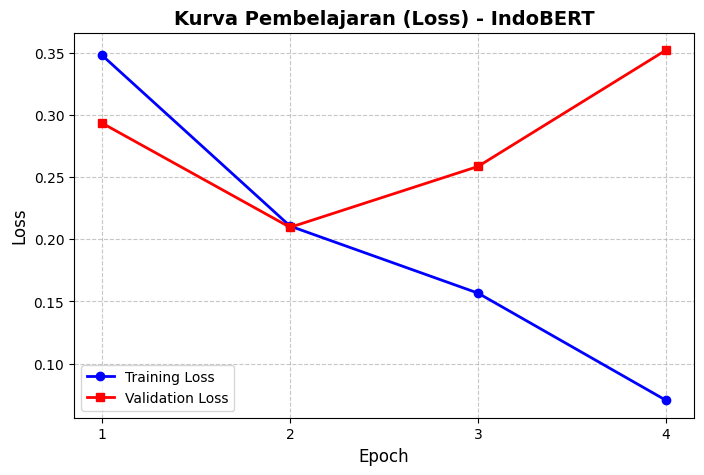

Menghitung prediksi untuk IndoBERT...


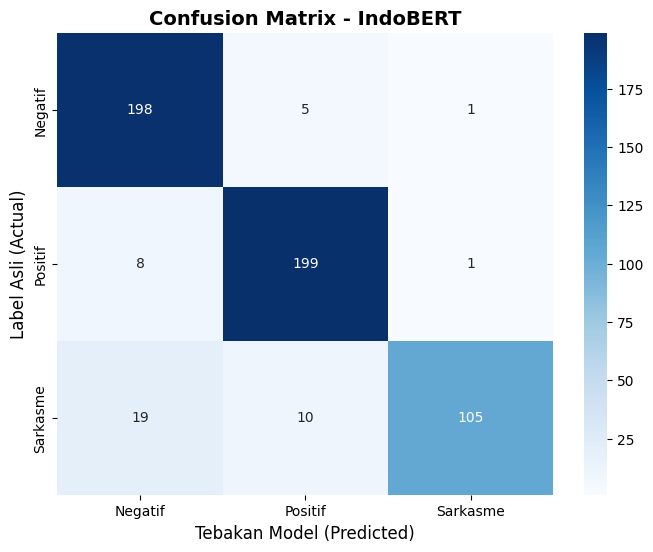

--------------------------------------------------


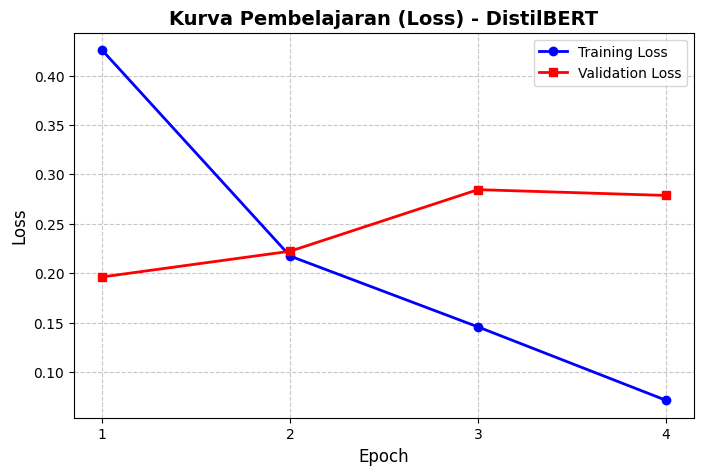

Menghitung prediksi untuk DistilBERT...


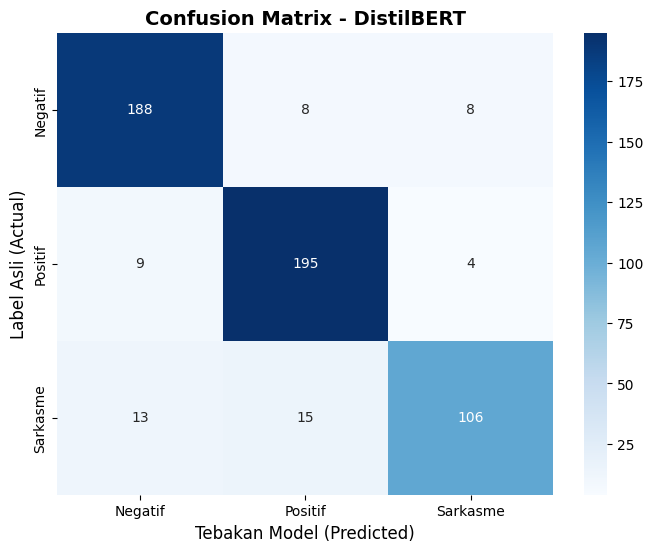

In [ ]:
# Confusion Matrix
def plot_confusion_matrix(trainer, dataset_test, model_name="Model"):
    print(f"Menghitung prediksi untuk {model_name}...")
    predictions, labels, _ = trainer.predict(dataset_test)

    # Handle DistilBERT (Tuple)
    if isinstance(predictions, tuple):
        preds = np.argmax(predictions[0], axis=-1)
    else:
        preds = np.argmax(predictions, axis=-1)

    # Matrix
    cm = confusion_matrix(labels, preds)
    class_names = ['Negatif', 'Positif', 'Sarkasme']

    # Heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)

    plt.title(f'Confusion Matrix - {model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Tebakan Model (Predicted)', fontsize=12)
    plt.ylabel('Label Asli (Actual)', fontsize=12)
    plt.show()


# LOSS
def plot_loss_curve(trainer, model_name="Model"):
    log_history = trainer.state.log_history

    # Step-level train loss (key='loss')
    step_logs = [log for log in log_history if 'loss' in log and 'eval_loss' not in log and 'train_loss' not in log]

    # Val loss per epoch
    val_logs = [log for log in log_history if 'eval_loss' in log]

    # Rata-rata train loss per epoch
    num_epochs = len(val_logs)
    steps_per_epoch = len(step_logs) // num_epochs if num_epochs > 0 else 1
    train_loss_per_epoch = []
    for i in range(num_epochs):
        epoch_steps = step_logs[i * steps_per_epoch:(i + 1) * steps_per_epoch]
        if epoch_steps:
            avg = sum(s['loss'] for s in epoch_steps) / len(epoch_steps)
            train_loss_per_epoch.append(avg)

    val_loss = [log['eval_loss'] for log in val_logs]
    epochs = range(1, num_epochs + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_loss_per_epoch, 'b-o', label='Training Loss', linewidth=2)
    plt.plot(epochs, val_loss, 'r-s', label='Validation Loss', linewidth=2)
    plt.title(f'Kurva Pembelajaran (Loss) - {model_name}', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.xticks(epochs)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

# Visualisasi IndoBERT
plot_loss_curve(trainer_indobert, "IndoBERT")
plot_confusion_matrix(trainer_indobert, test_dataset_indobert, "IndoBERT")

print("-" * 50)

# Visualisasi DistilBERT
plot_loss_curve(trainer_distil, "DistilBERT")
plot_confusion_matrix(trainer_distil, test_dataset_distil, "DistilBERT")

Comparison Table

In [ ]:
print("=" * 55)
print("       TABEL PERBANDINGAN AKHIR KEDUA MODEL")
print("=" * 55)
print(f"{'Metrik':<25} {'IndoBERT':>12} {'DistilBERT':>12}")
print("-" * 55)
print(f"{'Accuracy':<25} {results_test_indobert['eval_accuracy']:>12.4f} {results_test_distil['eval_accuracy']:>12.4f}")
print(f"{'Precision (Macro)':<25} {results_test_indobert['eval_precision']:>12.4f} {results_test_distil['eval_precision']:>12.4f}")
print(f"{'Recall (Macro)':<25} {results_test_indobert['eval_recall']:>12.4f} {results_test_distil['eval_recall']:>12.4f}")
print(f"{'F1 Macro':<25} {results_test_indobert['eval_f1_macro']:>12.4f} {results_test_distil['eval_f1_macro']:>12.4f}")
print(f"{'Inference Time (ms)':<25} {time_indobert:>12.4f} {time_distilbert:>12.4f}")
print(f"{'Training Time (menit)':<25} {train_time_indobert:>12.2f} {train_time_distilbert:>12.2f}")
print("=" * 55)
accuracy_drop = results_test_indobert['eval_accuracy'] - results_test_distil['eval_accuracy']
print(f"\nAccuracy Drop (IndoBERT - DistilBERT): {accuracy_drop:.4f}")
speedup = time_indobert / time_distilbert
print(f"Speedup DistilBERT vs IndoBERT       : {speedup:.2f}x lebih cepat")

       TABEL PERBANDINGAN AKHIR KEDUA MODEL
Metrik                        IndoBERT   DistilBERT
-------------------------------------------------------
Accuracy                        0.9194       0.8956
Precision (Macro)               0.9304       0.8960
Recall (Macro)                  0.9036       0.8834
F1 Macro                        0.9125       0.8883
Inference Time (ms)             8.9404       4.7383
Training Time (menit)            13.76         7.32

Accuracy Drop (IndoBERT - DistilBERT): 0.0238
Speedup DistilBERT vs IndoBERT       : 1.89x lebih cepat


Load Best Model from Drive

In [ ]:
path_model_indobert   = "./outputs/model_indobert"
path_model_distilbert = "./outputs/model_distilbert"

def get_best_checkpoint(path_model, nama_model):
    best_checkpoint_fixed = None

    checkpoints = [d for d in os.listdir(path_model) if d.startswith("checkpoint-")]

    if not checkpoints:
        print(f"[{nama_model}] Tidak ditemukan folder checkpoint di {path_model}")
        return None

    checkpoints.sort(key=lambda x: int(x.split("-")[1]))
    latest_checkpoint_folder = checkpoints[-1]

    trainer_state_path = os.path.join(path_model, latest_checkpoint_folder, "trainer_state.json")

    if os.path.exists(trainer_state_path):
        with open(trainer_state_path, "r") as f:
            state = json.load(f)

        best_checkpoint_raw = state.get("best_model_checkpoint", None)

        if best_checkpoint_raw:
            checkpoint_folder = os.path.basename(best_checkpoint_raw)
            best_checkpoint_fixed = os.path.join(path_model, checkpoint_folder)
            print(f"[{nama_model}] Best checkpoint ditemukan: {best_checkpoint_fixed}")
        else:
            print(f"[{nama_model}] best_model_checkpoint tidak tercatat di JSON.")
    else:
        print(f"[{nama_model}] File {trainer_state_path} tidak ditemukan.")

    return best_checkpoint_fixed

best_path_indobert   = get_best_checkpoint(path_model_indobert,   "IndoBERT")
best_path_distilbert = get_best_checkpoint(path_model_distilbert, "DistilBERT")

tokenizer_indobert   = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p1")
tokenizer_distilbert = AutoTokenizer.from_pretrained("cahya/distilbert-base-indonesian")

model_indobert_loaded   = AutoModelForSequenceClassification.from_pretrained(best_path_indobert)
model_distilbert_loaded = AutoModelForSequenceClassification.from_pretrained(best_path_distilbert)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_indobert_loaded.to(device).eval()
model_distilbert_loaded.to(device).eval()

print(f"\nSemua model berhasil di-load ke: {device}")

[IndoBERT] Best checkpoint ditemukan: /content/drive/MyDrive/Colab Notebooks/BERT_comparison/model_indobert_hasil/checkpoint-1292
[DistilBERT] Best checkpoint ditemukan: /content/drive/MyDrive/Colab Notebooks/BERT_comparison/model_distilbert_hasil/checkpoint-646


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/230k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Semua model berhasil di-load ke: cuda


Extract Predictions IndoBERT

In [ ]:
trainer_eval_indobert = Trainer(model=model_indobert_loaded)

print("Memprediksi data test menggunakan IndoBERT...")
output_loaded_indobert = trainer_eval_indobert.predict(test_dataset_indobert)

preds_indobert = output_loaded_indobert.predictions.argmax(-1)
labels_indobert = output_loaded_indobert.label_ids

df_analysis = pd.DataFrame({
    'Teks': df_test['text'].values,
    'Label_Asli': labels_indobert,
    'Label_Prediksi': preds_indobert
})

label_map_reverse = {0: 'Negatif', 1: 'Positif', 2: 'Sarkasme'}
df_analysis['Label_Asli'] = df_analysis['Label_Asli'].map(label_map_reverse)
df_analysis['Label_Prediksi'] = df_analysis['Label_Prediksi'].map(label_map_reverse)

df_error = df_analysis[df_analysis['Label_Asli'] != df_analysis['Label_Prediksi']]

sarcasm_missed = df_error[df_error['Label_Asli'] == 'Sarkasme']

# Tampilkan hasilnya
pd.set_option('display.max_colwidth', None)
print(f"\nTotal Sarkasme yang gagal ditebak IndoBERT: {len(sarcasm_missed)} data")
print("\n=== CONTOH SARKASME YANG GAGAL DITEBAK INDOBERT ===")
display(sarcasm_missed)

Memprediksi data test menggunakan IndoBERT...



Total Sarkasme yang gagal ditebak IndoBERT: 29 data

=== CONTOH SARKASME YANG GAGAL DITEBAK INDOBERT ===


,Teks,Label_Asli,Label_Prediksi
30,polisi baik hanya polisi tidur,Sarkasme,Negatif
35,terima kasih indonesia team sekalian yang main top legen . beri peluang raja malaysia angkat piala harini,Sarkasme,Positif
45,"kepala bapak kau sholeh,mati aja kau bodoh buat emosi satu indonesia aja kau eee",Sarkasme,Negatif
58,nelayan itu berangkat melaut malam hari dan kembali pada siang hari . lalu waktu jam 12 malam pergi berdua supir ke pantai siapa yang dia temui itu ya? ini namanya bohong pangkat 12,Sarkasme,Negatif
122,nu tidak pernah mengklaim mewakili segenap ummat muslim . nu justru sering diklaim oleh sebagian orang yang kurang percaya diri .,Sarkasme,Negatif
135,fakultas kedokteran dan keperawatan di jogja ini banyak biangeeet seimbang dengan kekurangan tim medis yang banyak buuaanget !!,Sarkasme,Positif
160,santun tapi pembohong !,Sarkasme,Negatif
167,di medan lagi ada gerakan . bergaya juga ya mantan kamu banyak yang peduli.,Sarkasme,Negatif
171,anies klaim 73% warga puas dengan kinerja pemprov dki . iya nies puas jadi korban php janji manies mu,Sarkasme,Negatif
178,setinggi pangkat apapun kalian bapak nyawa kawan kami tidak mampu kalian beli dengan gaji kalian seumur hidup .,Sarkasme,Negatif


Extract Predictions DistilBERT

In [ ]:
trainer_eval_distilbert = Trainer(model=model_distilbert_loaded)

print("Memprediksi data test menggunakan DistilBERT...")
output_loaded_distilbert = trainer_eval_distilbert.predict(test_dataset_distil)

if isinstance(output_loaded_distilbert.predictions, tuple):
    logits_distil = output_loaded_distilbert.predictions[0]
else:
    logits_distil = output_loaded_distilbert.predictions

preds_distilbert = logits_distil.argmax(-1)
labels_distilbert = output_loaded_distilbert.label_ids

df_analysis_distil = pd.DataFrame({
    'Teks': df_test['text'].values,
    'Label_Asli': labels_distilbert,
    'Label_Prediksi': preds_distilbert
})

label_map_reverse = {0: 'Negatif', 1: 'Positif', 2: 'Sarkasme'}
df_analysis_distil['Label_Asli'] = df_analysis_distil['Label_Asli'].map(label_map_reverse)
df_analysis_distil['Label_Prediksi'] = df_analysis_distil['Label_Prediksi'].map(label_map_reverse)

df_error_distil = df_analysis_distil[df_analysis_distil['Label_Asli'] != df_analysis_distil['Label_Prediksi']]

sarcasm_missed_distil = df_error_distil[df_error_distil['Label_Asli'] == 'Sarkasme']

pd.set_option('display.max_colwidth', None)
print(f"\nTotal Sarkasme yang gagal ditebak DistilBERT: {len(sarcasm_missed_distil)} data")
print("\n=== CONTOH SARKASME YANG GAGAL DITEBAK DISTILBERT ===")
display(sarcasm_missed_distil)

Memprediksi data test menggunakan DistilBERT...



Total Sarkasme yang gagal ditebak DistilBERT: 28 data

=== CONTOH SARKASME YANG GAGAL DITEBAK DISTILBERT ===


,Teks,Label_Asli,Label_Prediksi
13,astagfirullah medina zein make narkoba ..saya tidak kaget make narkoba nya saya kaget karena saya tidak tahu siapa pula medina zein,Sarkasme,Negatif
30,polisi baik hanya polisi tidur,Sarkasme,Negatif
35,terima kasih indonesia team sekalian yang main top legen . beri peluang raja malaysia angkat piala harini,Sarkasme,Positif
45,"kepala bapak kau sholeh,mati aja kau bodoh buat emosi satu indonesia aja kau eee",Sarkasme,Negatif
58,nelayan itu berangkat melaut malam hari dan kembali pada siang hari . lalu waktu jam 12 malam pergi berdua supir ke pantai siapa yang dia temui itu ya? ini namanya bohong pangkat 12,Sarkasme,Negatif
122,nu tidak pernah mengklaim mewakili segenap ummat muslim . nu justru sering diklaim oleh sebagian orang yang kurang percaya diri .,Sarkasme,Negatif
123,indonesiaku sedang berberdaya gunaan yang menolak perdamaian berarti mereka menolak nkri dan pancasila .,Sarkasme,Negatif
126,baru kali pertama atmosfir debat capres di indonesia ngalahin atmosfir final bola piala dunia !! jancok !!,Sarkasme,Positif
135,fakultas kedokteran dan keperawatan di jogja ini banyak biangeeet seimbang dengan kekurangan tim medis yang banyak buuaanget !!,Sarkasme,Positif
164,mending jadi pengusaha saja daripada negara ini jadi ancooor,Sarkasme,Negatif


Live Demo

In [ ]:
def classify_sentence(teks, model, tokenizer, nama_model="Model"):
    start_time = time.time()
    inputs = tokenizer(teks, return_tensors="pt", truncation=True, max_length=128, padding=True).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        pred_id = logits.argmax(dim=-1).item()

    end_time = time.time()
    inference_time = (end_time - start_time) * 1000
    label_map = {0: "Negatif", 1: "Positif", 2: "Sarkasme"}

    print(f"[{nama_model}]")
    print(f"Kalimat   : '{teks}'")
    print(f"Tebakan   : {label_map[pred_id]}")
    print(f"Waktu     : {inference_time:.2f} ms")
    print("-" * 40)

test_sentence = input("Masukkan satu kalimat: ")

classify_sentence(test_sentence, trainer_indobert.model, tokenizer_indobert, "IndoBERT")
classify_sentence(test_sentence, trainer_distil.model, tokenizer_distilbert, "DistilBERT")

Live Demo UI

In [ ]:
def text_classification_ui(text):
    if not text or not text.strip():
        return "Teks tidak boleh kosong.", "Teks tidak boleh kosong."

    label_map = {0: "Negatif", 1: "Positif", 2: "Sarkasme"}

    # IndoBERT
    start_time_indo = time.time()
    inputs_indobert = tokenizer_indobert(
        text, return_tensors="pt",
        truncation=True, max_length=128, padding=True
    ).to(device)
    with torch.no_grad():
        outputs_indo  = model_indobert_loaded(**inputs_indobert)
        pred_id_indo  = outputs_indo.logits.argmax(dim=-1).item()
    indobert_time = (time.time() - start_time_indo) * 1000

    # DistilBERT
    start_time_distil = time.time()
    inputs_distil = tokenizer_distilbert(
        text, return_tensors="pt",
        truncation=True, max_length=128, padding=True
    ).to(device)
    with torch.no_grad():
        outputs_distil = model_distilbert_loaded(**inputs_distil)
        pred_id_distil = outputs_distil.logits.argmax(dim=-1).item()
    distil_time = (time.time() - start_time_distil) * 1000

    result_indobert   = f"IndoBERT: {label_map[pred_id_indo]} ({indobert_time:.2f} ms)"
    result_distilbert = f"DistilBERT: {label_map[pred_id_distil]} ({distil_time:.2f} ms)"

    return result_indobert, result_distilbert

iface = gr.Interface(
    fn=text_classification_ui,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Ketik kalimat di sini...",
        label="Input Teks"
    ),
    outputs=[
        gr.Textbox(label="Hasil IndoBERT"),
        gr.Textbox(label="Hasil DistilBERT")
    ],
    title="Deteksi Sarkasme: IndoBERT vs DistilBERT",
    description="Masukkan kalimat untuk melihat perbandingan prediksi sentimen dan kecepatan inferensi."
)

iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c442986f4ab867eabb.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
